In [1]:
import subprocess
import sys

COLAB = "google.colab" in sys.modules


def _install(package):
    if COLAB:
        ans = input(f"Install { package }? [y/n]:")
        if ans.lower() in ["y", "yes"]:
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "--quiet", package]
            )
            print(f"{ package } installed!")


def _colab_install_missing_deps(deps):
    import importlib

    for dep in deps:
        if importlib.util.find_spec(dep) is None:
            if dep == "iris":
                dep = "scitools-iris"
            _install(dep)


deps = ["ioos_qc"]
_colab_install_missing_deps(deps)

In [2]:
import ioos_qc
print(ioos_qc.__version__)

0.1.dev812+g6f4439a2c


#   IOOS QARTOD on Glider Data
Created: 2026-10-02

Updated: 2026-10-22

During the 2026 Google Summer of Code, a project was [proposed to evaluate](https://github.com/ioos/gsoc/issues/102) the tests present in the [QARTOD glider manual](https://cdn.ioos.noaa.gov/media/2017/12/Manual-for-QC-of-Glider-Data_05_09_16.pdf), which had recently turned 10 years old. The final project was called ["Filling the gaps within the IOOS quality control schema for ocean glider data"](https://summerofcode.withgoogle.com/programs/2026/projects/bJGGUbsA) which led to a [series of investigative notebooks](https://github.com/Klankers/mau_gsoc_qartod) that did the following for tests listed within the manual:
1. Looked at the manual's description and assessed if it made sense.
2. Looked within the [IOOS QC codebase](https://github.com/ioos/ioos_qc/tree/main/ioos_qc) and assessed if it was authentic and genuine to the manual. If not, look at where the differences were and what they would do in practice.
3. Given the unknown recent activity of the manual's original authors, make additions or changes to the QARTOD toolbox to more comprehensively perform what is described in the manual.

This general procedure was done for the following tests:
1. Timing/Gap Test
2. Syntax Test
3. Location Test
4. Gross Range Test
5. Pressure Test
6. Climatology Test
14. (As ordered in the manual) Density Inversion Test

This notebook seeks to demonstrate how the tests can be used on ocean glider datasets. Unfortunately, the following tests were not assessed:

7. Spike Test
8. Rate of Change Test
9. Flat Line TEst
10. Multi-Variate Test
11. Attenuated Signal Test
12. Previous Profile Test
13. TS Curve/Space Test

As such, these tests will not be listed in this notebook unless updated at a later date.

Experimentation during the 2026 Google Summer of Code was commonly done on gliders using the [OG1 format](https://oceangliderscommunity.github.io/OG-format-user-manual/OG_Format.html). Plots, statistics, and any other outputs from this notebook are therefore entirely intended for educational purposes and are not intended to critically reflect on the dataset being used. Note that the results and settings present in this notebook may differ from those found at other institutions.

Data for this notebook is sourced from the Voice of the Ocean Foundation's ALSEAMAR *SeaExplorer* fleet, operating in the [Skagerrak](https://en.wikipedia.org/wiki/Skagerrak) between 2021 and 2026. This region is characterized by the interaction between deep, salty water from the [North Sea](https://en.wikipedia.org/wiki/North_Sea) interacting with fresh, relatively warm outflow from the [Baltic Sea](https://en.wikipedia.org/wiki/Baltic_Sea), passing through the [Danish Straits](https://en.wikipedia.org/wiki/Danish_Straits) and [Kattegat](https://en.wikipedia.org/wiki/Kattegat). This gives a temperature profile that is normally expected (warmest water at the surface), though the salinity profile is opposite of that typical in ocean gyres or open ocean (here, fresh water is on top).

The dataset to be used is [mission #109 of SeaExplorer number 044](https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/), operating for 20 days in September 2025.

This notebook is continued from part 2, which covers the Location Tests. This part covers the Gross Range, Percentile Range and Climatology Tests. The setup from part 1 is repeated below, followed by the overview figure as a quick refresher.

## Load the data
Starting with imports and loading the dataset.

In [3]:
#   For loading data
import pooch
import xarray as xr

#   Contains all of our tests
from ioos_qc import qartod

#   20261022: Extracting all the plotting code.
#   The plotting helpers live next to this notebook. The file name isn't a valid module name, so load it by path.
import importlib.util
spec = importlib.util.spec_from_file_location("plotting_helpers", "2026-10-22-QARTOD-help-plot.py")
plotting_helpers = importlib.util.module_from_spec(spec)
spec.loader.exec_module(plotting_helpers)

url = "https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/"
fname = "sea044_20250905T0639_delayed.nc"
filehash = "0bce25b78fc40bd7888a76909faa60b4f6490afd44b68a7f1f56c9d7611020ab"
#   VOTO's file hashes are not public as of September 2026. I've computed it using Python's 'hashlib'

download = pooch.retrieve(
    url=f"{url}{fname}",
    known_hash=f"sha256:{filehash}"
)
ds = xr.open_dataset(download)
ds

<xarray.Dataset> Size: 245MB
Dimensions:                             (N_MEASUREMENTS: 1699082)
Coordinates:
  * N_MEASUREMENTS                      (N_MEASUREMENTS) int64 14MB 0 ... 169...
    LATITUDE                            (N_MEASUREMENTS) float64 14MB ...
    LONGITUDE                           (N_MEASUREMENTS) float64 14MB ...
    TIME                                (N_MEASUREMENTS) datetime64[ns] 14MB ...
    DEPTH                               (N_MEASUREMENTS) float64 14MB ...
Data variables: (12/31)
    AD2CP_HEADING                       (N_MEASUREMENTS) float32 7MB ...
    AD2CP_PITCH                         (N_MEASUREMENTS) float32 7MB ...
    AD2CP_ROLL                          (N_MEASUREMENTS) float32 7MB ...
    BBP700                              (N_MEASUREMENTS) float32 7MB ...
    CHLA                                (N_MEASUREMENTS) float32 7MB ...
    DIVE_NUMBER                         (N_MEASUREMENTS) int64 14MB ...
    ...                                  ...
    SENSOR_CURRENT_PROFILERS_105527     float64 8B ...
    SENSOR_DISSOLVED_GAS_SENSORS_0095   float64 8B ...
    SENSOR_FLUOROMETERS_235280          float64 8B ...
    SENSOR_MICROSTRUCTURE_SENSORS_0496  float64 8B ...
    PROFILE_NUMBER                      (N_MEASUREMENTS) int64 14MB ...
    PROFILE_DIRECTION                   (N_MEASUREMENTS) int64 14MB ...
Attributes: (12/67)
    Conventions:                                CF-1.10, OG-1.0, Unidata Data...
    acknowledgement:                            This study used data collecte...
    agency:                                     Voice of the Ocean
    agency_role:                                contact point
    agency_role_vocabulary:                     http://vocab.nerc.ac.uk/colle...
    cdm_data_type:                              Trajectory
    ...                                         ...
    start_date:                                 20250905T0639
    basin:                                      Skagerrak
    total_dives:                                616
    dataset_id:                                 delayed_SEA044_M109
    data_url:                                   https://erddap.observations.v...
    variables:                                  ['AD2CP_HEADING', 'AD2CP_PITC...

In [4]:
from ioos_qc.qartod import QartodFlags  #   These are stored in a Class in qartod
print(dir(QartodFlags))
print(f"Unknown flag = {QartodFlags.UNKNOWN}")

#   Each flag is tied to a label and a color in the plotting helpers.
flag_style = plotting_helpers.flag_style

['FAIL', 'GOOD', 'MISSING', 'SUSPECT', 'UNKNOWN', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__']
Unknown flag = 2


In [5]:
order = plotting_helpers.order
print(order)

[2, 1, 9, 3, 4]


In [6]:
import gsw
import numpy as np
ds["PSAL"] = gsw.SP_from_C(ds.CNDC, ds.TEMP, ds.PRES)
ds["SA"] = gsw.SA_from_SP(ds.PSAL, ds.PRES, ds.LONGITUDE, ds.LATITUDE)
ds["CT"] = gsw.CT_from_t(ds.SA, ds.TEMP, ds.PRES)
ds["SIGMA0"] = gsw.sigma0(ds.SA, ds.CT)

time = ds.TIME.values
pres = ds.PRES.values
temp = ds.TEMP.values
psal = ds.PSAL.values
sigma0 = ds.SIGMA0.values
profile = ds.PROFILE_NUMBER.values
direction = ds.PROFILE_DIRECTION.values  # 1 = descending, -1 = ascending

print(f"{time.size} measurements in {np.unique(profile).size} profiles")
print(f"{np.datetime_as_string(time[0], unit='m')} to {np.datetime_as_string(time[-1], unit='m')}")

1699082 measurements in 1232 profiles
2025-09-05T06:39 to 2025-09-25T09:24


In [7]:
#   This is a quick helper function that we can pass any flags into and get flag information out of
def flag_counts(flags, name=""):
    flags = np.ma.getdata(flags)
    parts = [
        f"{flag_style[f][0]}={np.count_nonzero(flags == f):,}" for f in order if np.any(flags == f)
    ]
    print(f"{name:<28s}" + ", ".join(parts))

In [8]:
extent = (8.8, 11.6, 57.4, 59.2)  # lon_min, lon_max, lat_min, lat_max

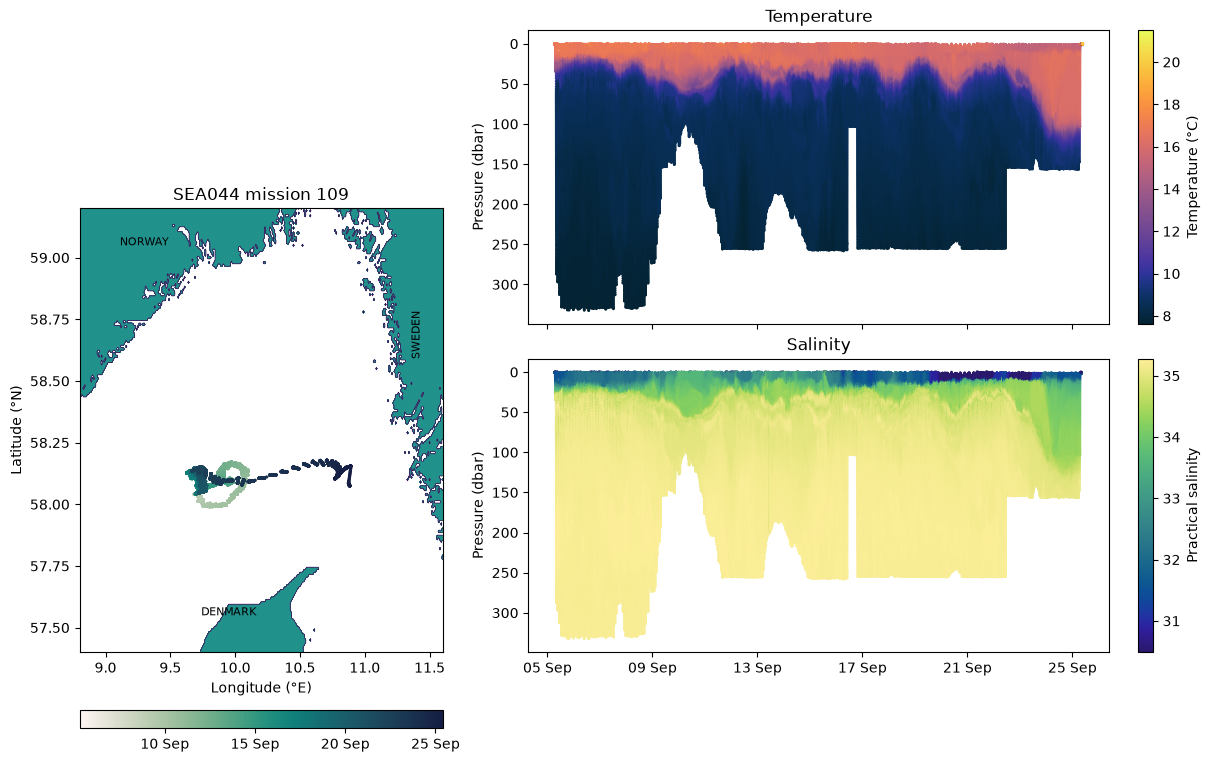

In [9]:
fig, axs = plotting_helpers.overview_figure(ds.LONGITUDE.values, ds.LATITUDE.values, time, pres, temp, psal, extent)

## Gross Range Test
The `gross_range_test` is perhaps the most important test that is also the easiest to understand. Flag values that aren't within a specific range, with some optional tolerance between being a suspicious value and a bad value.

This has been expanded into the percentile range test (discussed later), for working with variables where maybe the bounds aren't known.

In [10]:
for var in ["TEMP", "CHLA"]:
    attrs = ds[var].attrs
    print(f"{var}: valid range {attrs['valid_min']} to {attrs['valid_max']} {attrs['units']}")

TEMP: valid range -5.0 to 42.0 Degrees Celsius
CHLA: valid range 0.0 to 50.0 mg m-3


A handy attribute present in the OG1 format is the `valid_min` and `valid_max`, which is something that echoes manufacturer or institutional specifications. These can be a good start in some cases without doing the percentile range test.

This data is from the Skagerrak, which typically doesn't get as warm or salty as a gyre. We can initialize our `fail_span` with the valid ranges, and then further constrain to about 7-22 °C.

In [11]:
temp_fail = (float(ds.TEMP.attrs["valid_min"]), float(ds.TEMP.attrs["valid_max"]))
temp_suspect = (7, 22)
flags_temp = qartod.gross_range_test(temp, fail_span=temp_fail, suspect_span=temp_suspect)
flag_counts(flags_temp, "TEMP:")

TEMP:                       GOOD=1,698,837, MISSING=237, SUSPECT=8


In [12]:
print(np.where(flags_temp == 3))

(array([1694431, 1694432, 1694433, 1694434, 1694435, 1694436, 1694437,
       1694438]),)


Looks like there aren't too many bad flags here - they're all at the end.

Let's visualize these ranges in a couple of different ways. First - the most intuitive way, looking at where the value itself steps into each one as a function of time. Second, as a histogram to show how often the bound is being violated. Showing the distribution from a depth perspective is also helpful - given many sensors can have problems at the surface. It's nice to know *where* the issue is happening.

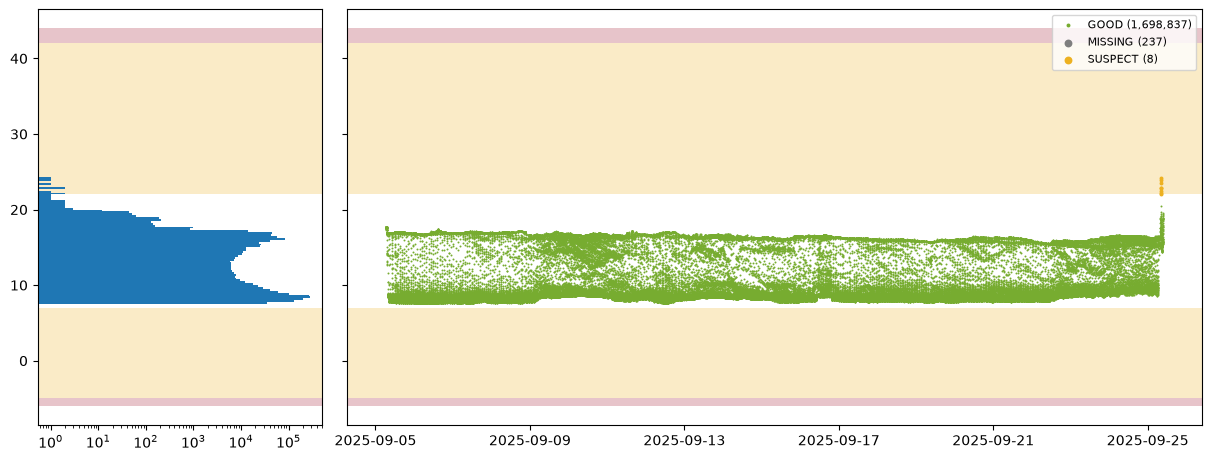

In [13]:
fig, axs = plotting_helpers.gross_range_figure_val(
    time, temp, flags_temp, temp_fail, temp_suspect,
    bins=np.linspace(-6, 44, 201),
)

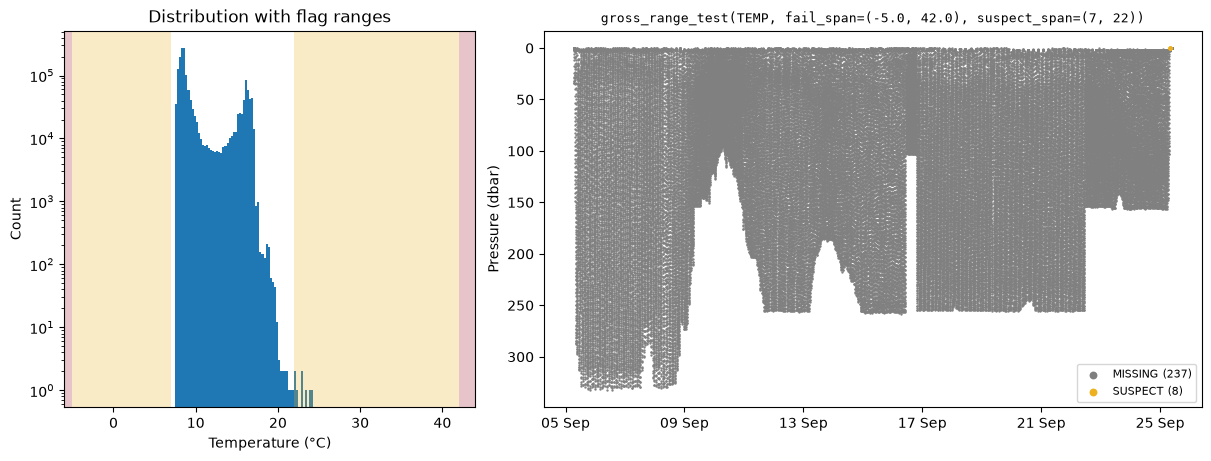

In [14]:
fig, axs = plotting_helpers.gross_range_figure_pres(
    time, pres, temp, flags_temp, temp_fail, temp_suspect, "Temperature (°C)",
    f"gross_range_test(TEMP, fail_span={temp_fail}, suspect_span={temp_suspect})",
    bins=np.linspace(-6, 44, 201),
)

So we can see that the 8 suspect values are at the very end, when the glider is being recovered or is at the surface. This will likely be different for an optical sensor, which is more likely to get spikes.

Note: There's a chlorophyll value of ±500 in here - cutting down to a smaller window using `np.clip` helps make things more legible.

In [15]:
chla = ds.CHLA.values
chla_fail = (float(ds.CHLA.attrs["valid_min"]), float(ds.CHLA.attrs["valid_max"]))
chla_suspect = (0, 10)
flags_chla = qartod.gross_range_test(chla, fail_span=chla_fail, suspect_span=chla_suspect)
print(f"Fail: {chla_fail}, Sus: {chla_suspect}")
print(f"{np.nanmin(chla)}-{np.nanmax(chla)}")
flag_counts(flags_chla, "CHLA:")
print(f"Of which pinned at +/-500: {np.count_nonzero(np.abs(chla) == 500)}")

Fail: (0.0, 50.0), Sus: (0, 10)
-500.0-500.0
CHLA:                       GOOD=1,690,361, MISSING=585, SUSPECT=676, FAIL=7,460
Of which pinned at +/-500: 35


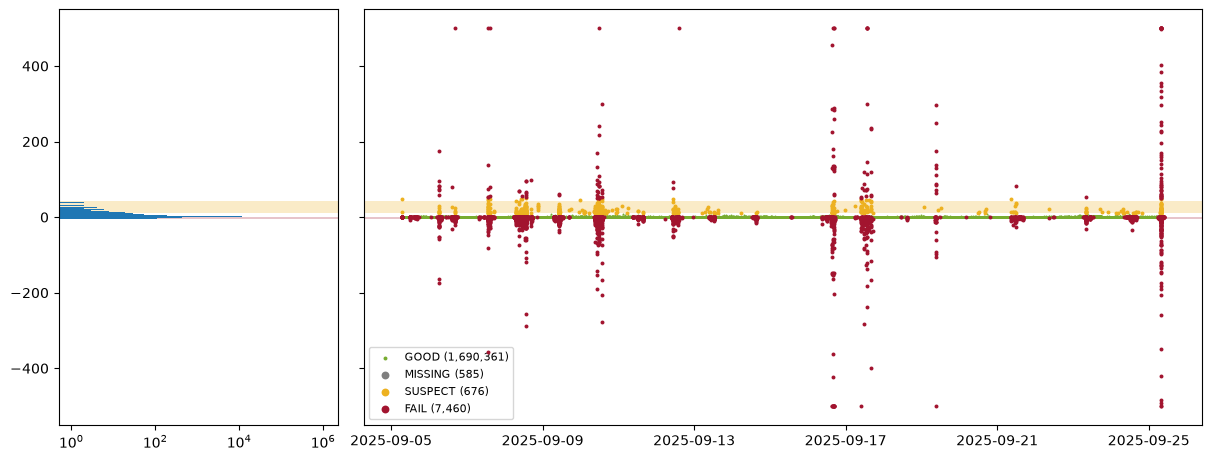

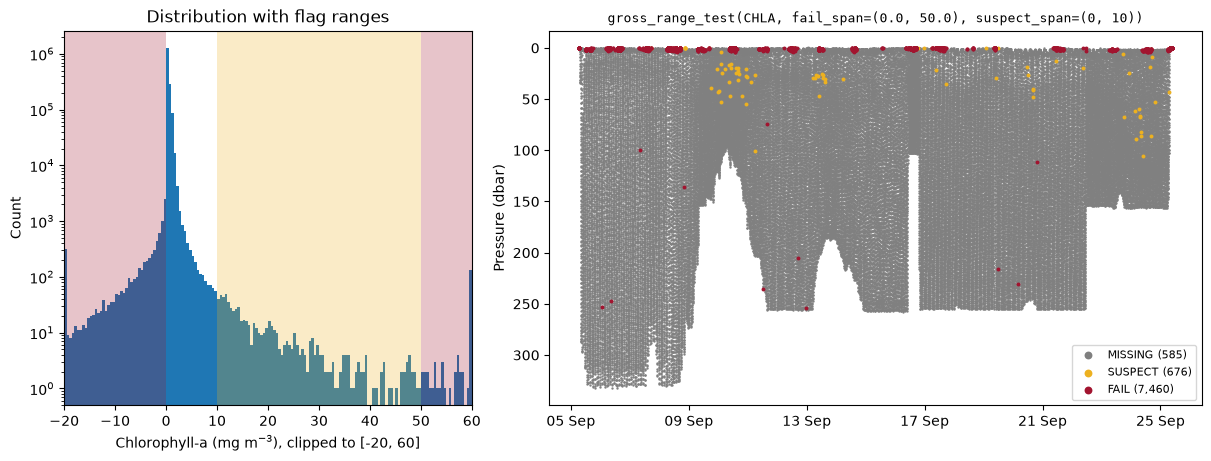

In [16]:
fig, axs = plotting_helpers.gross_range_figure_val(
    time, chla, flags_chla, chla_fail, chla_suspect,
    bins=np.linspace(-6, 44, 201),
)
fig, axs = plotting_helpers.gross_range_figure_pres(
    time, pres, np.clip(chla, -20, 60), flags_chla, chla_fail, chla_suspect,
    "Chlorophyll-a (mg m$^{-3}$), clipped to [-20, 60]",
    f"gross_range_test(CHLA, fail_span={chla_fail}, suspect_span={chla_suspect})",
    bins=np.linspace(-20, 60, 161),
)

So in this case, we can see that there are lots of recurring issues with chlorophyll that are happening at the surface, but the ocassional issues are happening at depth - possibly optical spikes that could be ignored, given they don't have obvious trends from a depth perspective.

## Percentile Range Test
The `percentile_range_test` grew from the `gross_range_test`, mostly as a way of avoiding a fixed spans and being bounded by the data itself. The user can define `low` and `hi_percentiles` for the data, widened by an optional `pad` argument, which will define the flagging. These default to the 5th and 95th percentiles with a `pad` of 0.

It's worth noting that this `pad` is in whatever unit the variable is. So for example, if one were to do flagging from the 1st and 99th percentiles for temperature, you could add a 1 °C padding to this to reduce the amount of flagging that is done by values that could be totally statistically fine (otherwise, you're guaranteed to flag 2% of the data).

Because of the statistical nature of this test, there are no `fail` flags assigned as there are for the `gross_range_test`.

In [17]:
pct_runs = {
    "defaults (5th-95th)": {},
    "1st-99th, pad = 1 °C": {"low_percentile": 1, "hi_percentile": 99, "pad": 1},
}
pct_flags = {name: qartod.percentile_range_test(temp, **kw) for name, kw in pct_runs.items()}
for name, flags in pct_flags.items():
    flag_counts(flags, name)

defaults (5th-95th)         GOOD=1,528,995, MISSING=237, SUSPECT=169,850
1st-99th, pad = 1 °C        GOOD=1,697,989, MISSING=237, SUSPECT=856


By loosening the statistical restrictions and adding a padding value, the number of suspect points has dropped signicantly. The `pad` value is why the value is less than 2% of the total data size.

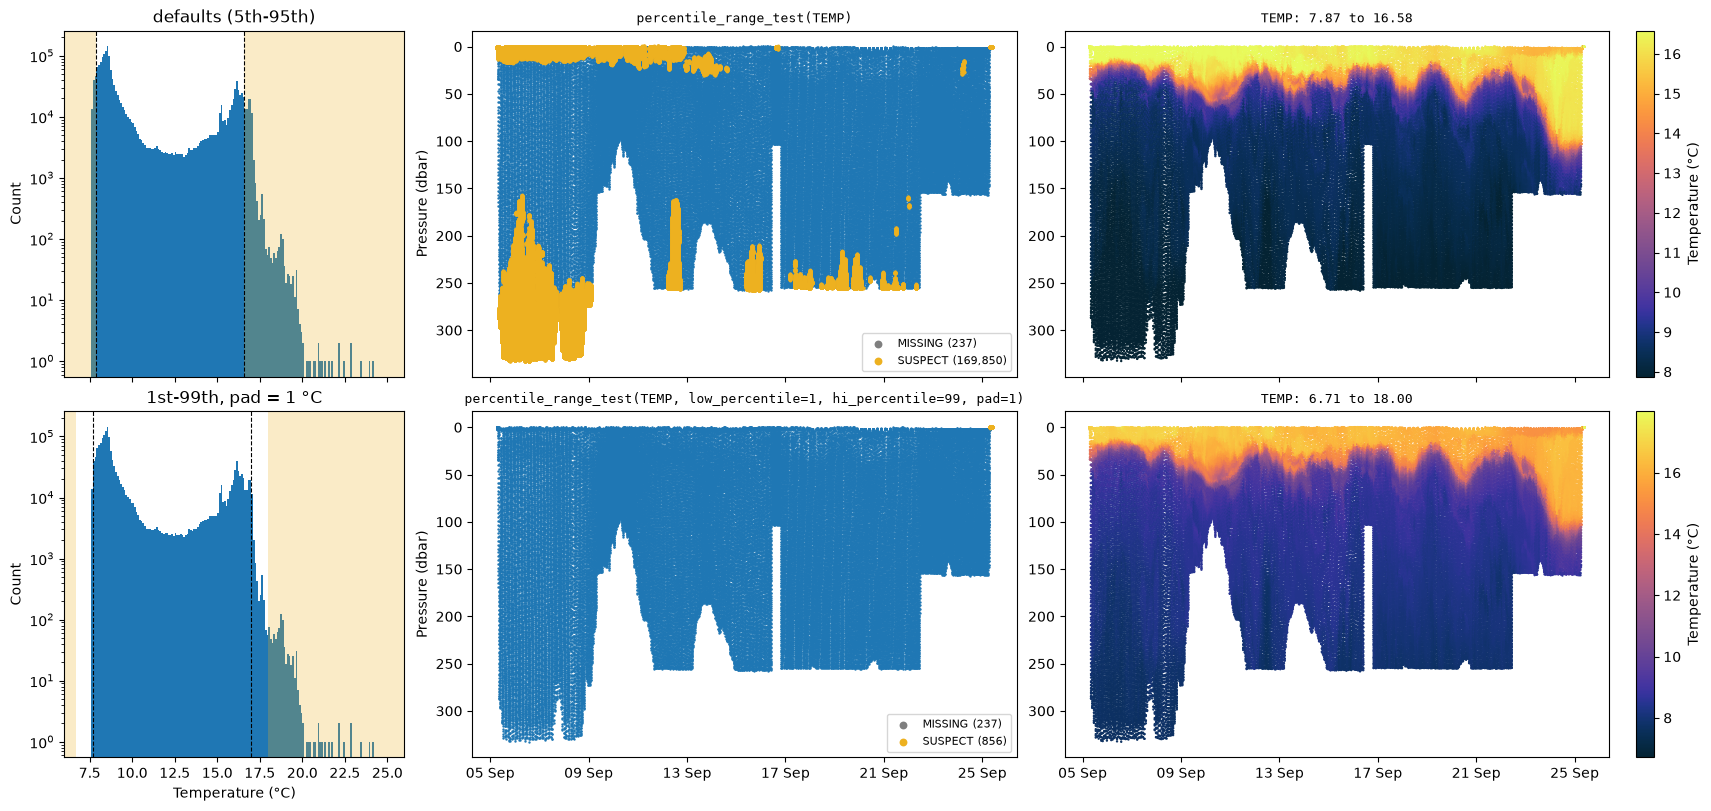

In [18]:
fig, axs = plotting_helpers.percentile_range_figure(time, pres, temp, pct_runs, pct_flags, bins=np.linspace(6, 26, 201))

As you can see, the defaults are flagging about 10% of the data, mostly because the values early and deep are *too cold*, as indicated in the more intense colorbar limits in the last column. This is loosened slightly with the 1-99 percentile and by introducing a padded value.
* Increasing the percentile tolerance - shifted the vertical dotted boundaries outwards in the first column and loosened the colorbar in the final column.
* Increasing the padding provided a buffer zone between the percentile tolerance and where the suspect values began.

This new range is about 6-17.9 °C, which is similar to what we assigned for the suspect range in the `gross_range_test`.

However, we can still see that the points at the very end (near the recovery or at the surface) is where temperature is being flagged even with our tolerance changes. That's good - it informs the user that they're approaching something without necessarily knowing what it should be.

## Climatology Test
The climatology test is similar to the `gross_range_test` in that it's like pairing a series of them together based on particular spatiotemporal domains. This uses a time span (`tspan`), and an optional depth span (`zspan`) for flagging specific sections of the data.

Historically, it has been implemented by a `ClimatologyConfig` object, then manually adding each config. During the 2026 Google Summer of Code, this was simplified to handle a list of dictionaries. In this section, we'll walk through it both ways. Both the legacy option (`ClimatologyConfig`), and the latest version as a series of dictionaries.

We'll start by building a series of depth slizes with `zspan` and different temperature tolerances, `vspan`, for a fixed time period (let's say a month). Just throwing out some rough estimates of the Skagerrak, the mixed layer can be vary but we can start with a 30 m depth guess.

Depth is using meters, so we'll want to convert from pressure using `gsw`.

In [19]:
depth = -gsw.z_from_p(pres, ds.LATITUDE.values)

clim = qartod.ClimatologyConfig()
clim.add(tspan=("2025-09-01", "2025-10-01"), zspan=(0, 30), vspan=(10, 20))
clim.add(tspan=("2025-09-01", "2025-10-01"), zspan=(30, 400), vspan=(7, 16))
flags_clim = qartod.climatology_test(clim, temp, time, depth)
flag_counts(flags_clim, "Climatology:")

Climatology:                UNKNOWN=2,346, GOOD=1,659,931, MISSING=237, SUSPECT=36,568


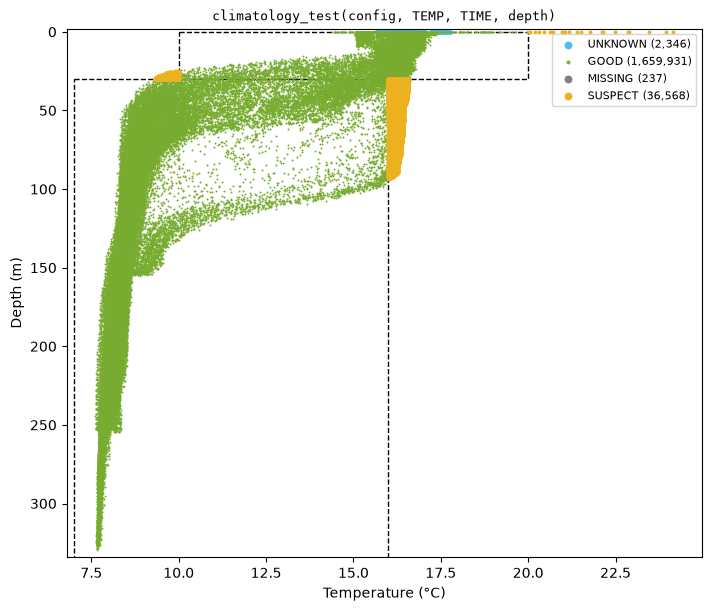

In [20]:
fig, ax = plotting_helpers.climatology_figure(
    temp, depth, flags_clim, boxes=[((0, 30), (10, 20)), ((30, 400), (7, 16))],
)

So we can see that we've got bounding conditions that might be too lenient at the surface, and too strict at depth, depending on when most of these high temperature values at 100 m are showing up.

It's also worth noting that the climatology is a test that only runs on the subsection of the data that we've specified. There are still about 2,300 points that aren't assessed by this - since these spatioemporal periods have not been defined.

Moving on to an example of passing in dictionaries directly to the `climatology_config` parser, which checks the `period` and individual spans. Let's designate an additional span that defines the `fail` span.

In [21]:
clim_windows = qartod.climatology_config([
    {"tspan": ("2025-09-01", "2025-10-01"), "vspan": (6, 22), "zspan": (-5, 400)},  # catch-all, applied first
    {"tspan": (9, 9), "period": "month", "vspan": (10, 20), "fspan": (5, 22), "zspan": (0, 30)},
    {"tspan": (9, 9), "period": "month", "vspan": (7, 16), "zspan": (30, 400)},
])

for window in clim_windows:
    print(window)

flags_clim_windows = qartod.climatology_test(clim_windows, temp, time, depth)
flag_counts(flags_clim_windows, "Climatology (windows):")

{'tspan': Span(minv=Timestamp('2025-09-01 00:00:00'), maxv=Timestamp('2025-10-01 00:00:00')), 'vspan': Span(minv=6, maxv=22), 'fspan': None, 'zspan': Span(minv=-5, maxv=400), 'period': None}
{'tspan': Span(minv=9, maxv=9), 'vspan': Span(minv=10, maxv=20), 'fspan': Span(minv=5, maxv=22), 'zspan': Span(minv=0, maxv=30), 'period': 'month'}
{'tspan': Span(minv=9, maxv=9), 'vspan': Span(minv=7, maxv=16), 'fspan': None, 'zspan': Span(minv=30, maxv=400), 'period': 'month'}
Climatology (windows):      GOOD=1,662,277, MISSING=237, SUSPECT=36,560, FAIL=8


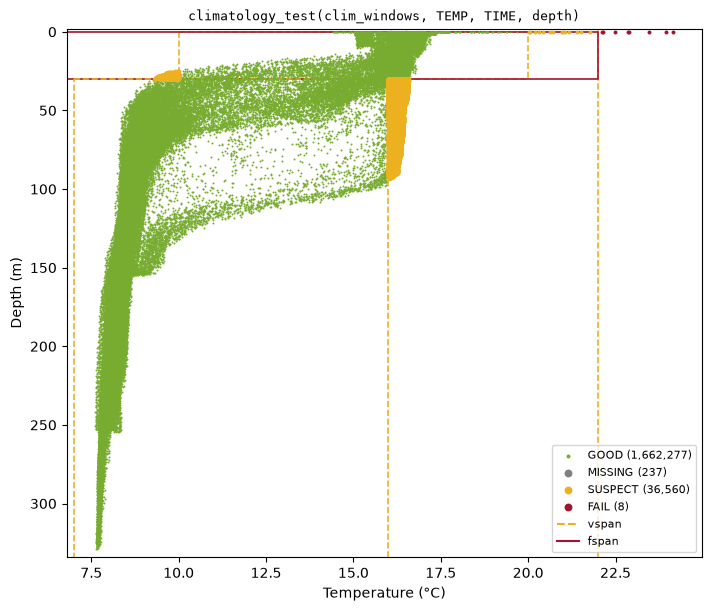

In [22]:
fig, ax = plotting_helpers.climatology_windows_figure(temp, depth, flags_clim_windows, clim_windows)

So the `fspan` window has expanded the range in the mixed layer for that period.

This notebook is continued in part 4, which covers the Pressure Test and the Density Inversion Test.